# 01 – Carga de datos y análisis exploratorio (EDA)
**Proyecto:** Clasificación de enfermedades de la yuca con modelos preentrenados
**Dataset:** TensorFlow Datasets – `cassava` (iCassava 2019)

**Qué hace este notebook**
1. Carga el dataset con sus particiones oficiales.
2. Cuenta las imágenes por clase en cada partición (desbalance).
3. Revisa resoluciones originales.
4. Muestra ejemplos de cada clase.
5. Busca imágenes duplicadas dentro y entre particiones (posible fuga de datos).

> En Colab: **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)**.

In [ ]:
# ============================================================
# CONFIGURACIÓN DEL PROTOCOLO (igual en todos los notebooks)
# ============================================================
import os, time, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

SEED = 42          # semilla fija -> resultados reproducibles
IMG = 224          # tamaño de entrada estándar de MobileNetV2 / ResNet
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)   # fija la semilla de Python, NumPy y TensorFlow
os.makedirs("results", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Instalar dependencia faltante necesaria para TFDS
!pip install -q importlib_resources

# ============================================================
# CARGA DEL DATASET (particiones oficiales de TFDS)
# ============================================================
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    as_supervised=True,      # devuelve pares (imagen, etiqueta)
    with_info=True,
)
CLASES = info.features["label"].names   # ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
N_CLASES = len(CLASES)
print("Clases:", CLASES)
print("Train:", info.splits["train"].num_examples,
      "| Val:", info.splits["validation"].num_examples,
      "| Test:", info.splits["test"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Train: 5656 | Val: 1889 | Test: 1885


## 1. Distribución de clases
**Por qué importa:** si una clase tiene muchas más fotos, el modelo tiende a predecirla siempre.
Por eso la métrica principal es **macro-F1** y no accuracy.

In [ ]:
def contar(ds):
    etiquetas = np.array([y for _, y in tfds.as_numpy(ds)])
    return np.bincount(etiquetas, minlength=N_CLASES)

conteos = {"train": contar(ds_train), "validation": contar(ds_val), "test": contar(ds_test)}

print(f"{'clase':10s}" + "".join(f"{p:>12s}" for p in conteos))
for i, c in enumerate(CLASES):
    print(f"{c:10s}" + "".join(f"{conteos[p][i]:12d}" for p in conteos))
print(f"{'TOTAL':10s}" + "".join(f"{conteos[p].sum():12d}" for p in conteos))

# Porcentajes en entrenamiento
for i, c in enumerate(CLASES):
    print(f"{c:8s}: {100 * conteos['train'][i] / conteos['train'].sum():5.1f} % del entrenamiento")

clase            train  validation        test
cbb                466         156         155
cbsd              1443         482         481
cgm                773         258         258
cmd               2658         887         886
healthy            316         106         105
TOTAL             5656        1889        1885
cbb     :   8.2 % del entrenamiento
cbsd    :  25.5 % del entrenamiento
cgm     :  13.7 % del entrenamiento
cmd     :  47.0 % del entrenamiento
healthy :   5.6 % del entrenamiento


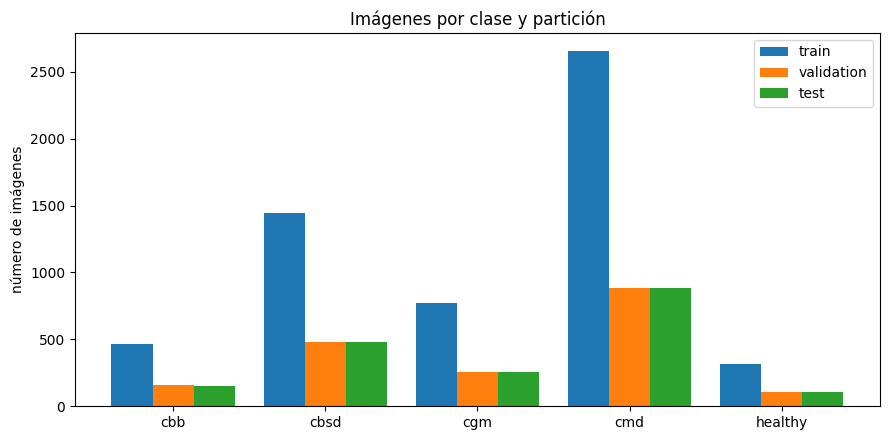

Razón de desbalance (mayor/menor) en train: 8.4 veces


In [ ]:
# Gráfico de barras del desbalance
x = np.arange(N_CLASES); w = 0.27
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (p, v) in enumerate(conteos.items()):
    ax.bar(x + (k - 1) * w, v, w, label=p)
ax.set_xticks(x); ax.set_xticklabels(CLASES)
ax.set_ylabel("número de imágenes"); ax.set_title("Imágenes por clase y partición")
ax.legend(); plt.tight_layout()
plt.savefig("results/eda_distribucion_clases.png", dpi=120)
plt.show()

# Proporción entre la clase más grande y la más pequeña
tr = conteos["train"]
print(f"Razón de desbalance (mayor/menor) en train: {tr.max() / tr.min():.1f} veces")

## 2. Resolución de las imágenes originales
Se revisa si las fotos tienen tamaños distintos. Todas se llevarán a 224×224 en el preprocesamiento.

In [ ]:
formas = np.array([img.shape[:2] for img, _ in tfds.as_numpy(ds_train.take(500))])
alturas, anchos = formas[:, 0], formas[:, 1]
print("Muestra de 500 imágenes de entrenamiento")
print(f"Alto  -> min {alturas.min()}, max {alturas.max()}, media {alturas.mean():.0f}")
print(f"Ancho -> min {anchos.min()}, max {anchos.max()}, media {anchos.mean():.0f}")
unicas, veces = np.unique(formas, axis=0, return_counts=True)
for f, v in sorted(zip(map(tuple, unicas), veces), key=lambda t: -t[1])[:5]:
    print(f"  tamaño {f}: {v} imágenes")

Muestra de 500 imágenes de entrenamiento
Alto  -> min 500, max 942, media 573
Ancho -> min 499, max 1185, media 618
  tamaño (np.int64(666), np.int64(500)): 116 imágenes
  tamaño (np.int64(500), np.int64(888)): 73 imágenes
  tamaño (np.int64(500), np.int64(666)): 60 imágenes
  tamaño (np.int64(500), np.int64(625)): 57 imágenes
  tamaño (np.int64(500), np.int64(500)): 37 imágenes


## 3. Ejemplos de cada clase

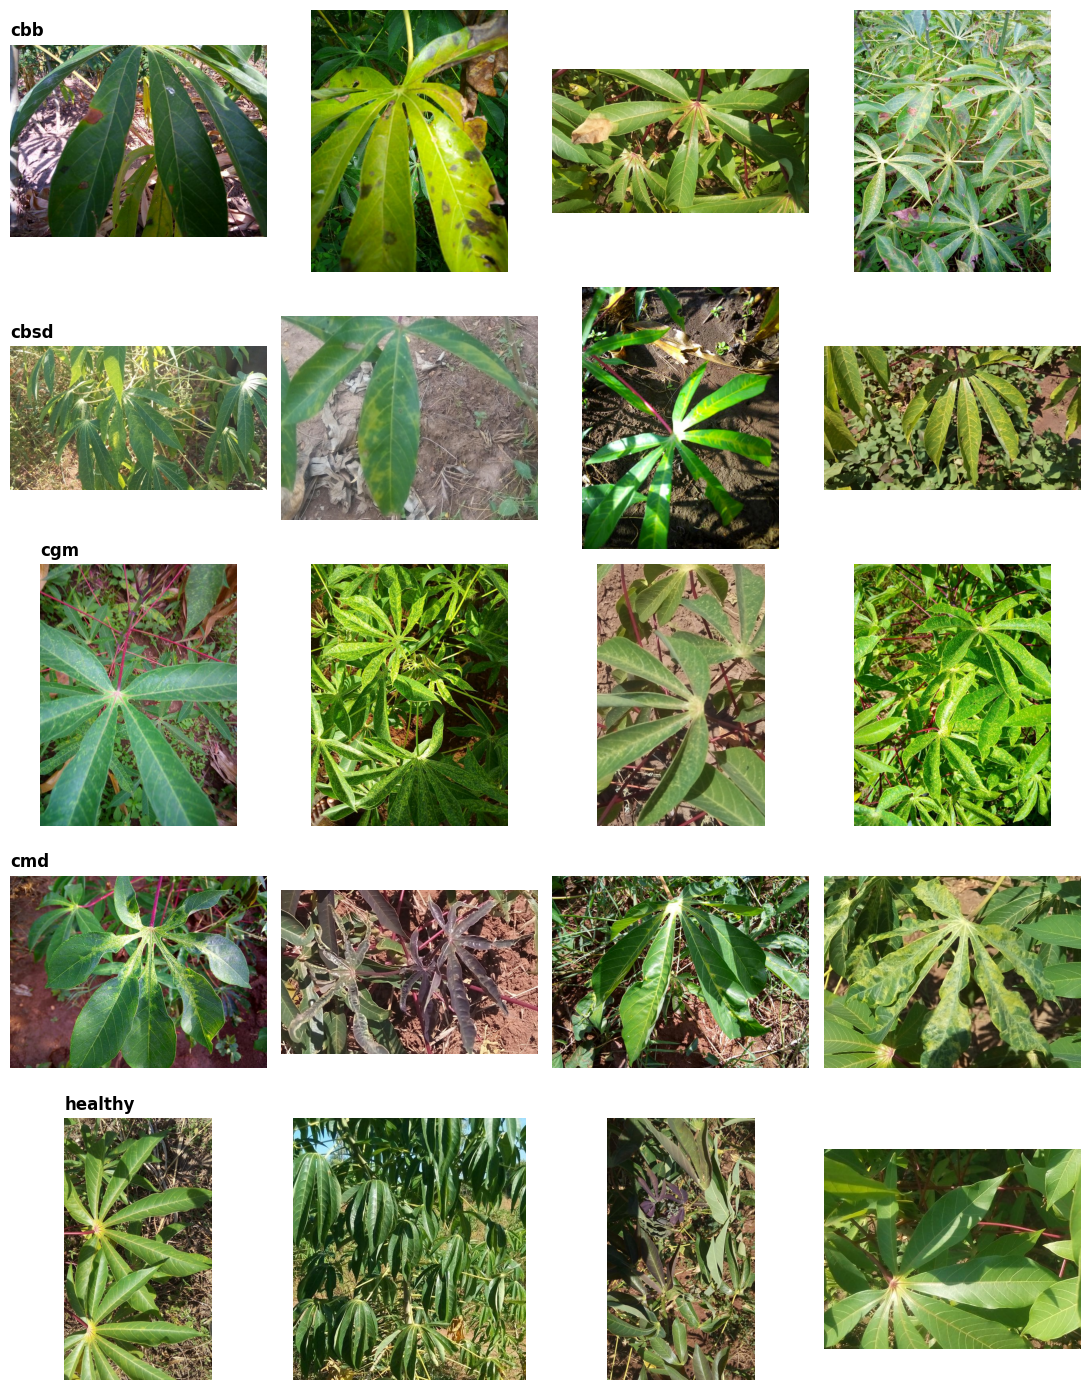

In [ ]:
ejemplos = {i: [] for i in range(N_CLASES)}
for img, y in tfds.as_numpy(ds_train):
    if len(ejemplos[y]) < 4:
        ejemplos[y].append(img)
    if all(len(v) == 4 for v in ejemplos.values()):
        break

fig, axs = plt.subplots(N_CLASES, 4, figsize=(11, 14))
for i in range(N_CLASES):
    for j in range(4):
        axs[i, j].imshow(ejemplos[i][j]); axs[i, j].axis("off")
    axs[i, 0].set_title(CLASES[i], loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("results/eda_ejemplos_clases.png", dpi=100)
plt.show()

## 4. Búsqueda de duplicados exactos
Se calcula una "huella" (hash MD5) de los píxeles de cada imagen.
Si dos imágenes tienen la misma huella, son idénticas.
**Duplicados entre entrenamiento y prueba = fuga de datos** (resultados falsamente buenos).

*Limitación:* solo detecta copias exactas, no fotos casi iguales (recortes, otra toma de la misma planta).

In [ ]:
def huellas(ds):
    return [hashlib.md5(img.tobytes()).hexdigest() for img, _ in tfds.as_numpy(ds)]

t0 = time.time()
h = {"train": huellas(ds_train), "validation": huellas(ds_val), "test": huellas(ds_test)}
print(f"Huellas calculadas en {time.time() - t0:.0f} s")

for p, lista in h.items():
    print(f"Duplicados dentro de {p}: {len(lista) - len(set(lista))}")

s = {p: set(v) for p, v in h.items()}
print("Compartidas train–validation:", len(s["train"] & s["validation"]))
print("Compartidas train–test:      ", len(s["train"] & s["test"]))
print("Compartidas validation–test: ", len(s["validation"] & s["test"]))

Huellas calculadas en 42 s
Duplicados dentro de train: 18
Duplicados dentro de validation: 2
Duplicados dentro de test: 1
Compartidas train–validation: 11
Compartidas train–test:       10
Compartidas validation–test:  4


In [ ]:
# Guardar el resumen del EDA
resumen = {
    "dataset": "tfds cassava",
    "version": str(info.version),
    "clases": CLASES,
    "conteos": {p: v.tolist() for p, v in conteos.items()},
    "duplicados_internos": {p: len(v) - len(set(v)) for p, v in h.items()},
    "compartidas_train_test": len(s["train"] & s["test"]),
    "compartidas_train_val": len(s["train"] & s["validation"]),
}
with open("results/eda_resumen.json", "w") as f:
    json.dump(resumen, f, indent=2)
print(json.dumps(resumen, indent=2))

{
  "dataset": "tfds cassava",
  "version": "0.1.0",
  "clases": [
    "cbb",
    "cbsd",
    "cgm",
    "cmd",
    "healthy"
  ],
  "conteos": {
    "train": [
      466,
      1443,
      773,
      2658,
      316
    ],
    "validation": [
      156,
      482,
      258,
      887,
      106
    ],
    "test": [
      155,
      481,
      258,
      886,
      105
    ]
  },
  "duplicados_internos": {
    "train": 18,
    "validation": 2,
    "test": 1
  },
  "compartidas_train_test": 10,
  "compartidas_train_val": 11
}


In [ ]:
# ============================================================
# ETIQUETAS DE LOS DUPLICADOS Y LISTA DE EXCLUSIÓN
# ============================================================
etiq = {p: [int(y) for _, y in tfds.as_numpy(d)] for p, d in
        [("train", ds_train), ("validation", ds_val), ("test", ds_test)]}

# ¿Una misma imagen aparece con etiquetas distintas?
por_huella = {}
for p in h:
    for hh, y in zip(h[p], etiq[p]):
        por_huella.setdefault(hh, set()).add(y)
conflictos = {hh: sorted(CLASES[i] for i in ys) for hh, ys in por_huella.items() if len(ys) > 1}
print("Imágenes repetidas con etiquetas DISTINTAS:", len(conflictos))
for hh, cl in list(conflictos.items())[:10]:
    print("  ", hh[:10], cl)

# Exclusión: se recorre train -> validation -> test y se quita lo ya visto
vistos, excluidas = set(), {}
for p in ["train", "validation", "test"]:
    excluidas[p] = []
    for i, hh in enumerate(h[p]):
        if hh in vistos:
            excluidas[p].append(i)
        vistos.add(hh)
    print(f"{p}: se excluyen {len(excluidas[p])} -> quedan {len(h[p]) - len(excluidas[p])}")

with open("results/indices_excluidos.json", "w") as f:
    json.dump({"criterio": "duplicado exacto (MD5) ya visto en una partición anterior o antes en la misma",
               "excluidos": excluidas, "conflictos_de_etiqueta": len(conflictos)}, f, indent=2)

Imágenes repetidas con etiquetas DISTINTAS: 18
   cfdcf7c871 ['cbb', 'cbsd', 'cgm']
   57d4d43b50 ['cbsd', 'cgm']
   a5dccf5b4d ['cbb', 'cbsd', 'cgm']
   e3da7c6ed5 ['cbb', 'cbsd', 'cgm']
   580a16cbc7 ['cbb', 'cbsd', 'cgm']
   76cdd2a598 ['cbb', 'cbsd', 'cgm']
   dca21d7015 ['cbb', 'cbsd', 'cgm']
   099bbd22be ['cbb', 'cbsd', 'cgm']
   8bdb019315 ['cbb', 'cbsd', 'cgm']
   829e01c5c9 ['cbb', 'cbsd', 'cgm']
train: se excluyen 18 -> quedan 5638
validation: se excluyen 13 -> quedan 1876
test: se excluyen 11 -> quedan 1874


## Conclusiones del EDA
- **Desbalance fuerte:** CMD concentra el 47,0 % del entrenamiento (2.658 imágenes), mientras que healthy tiene solo el 5,6 % (316) y CBB el 8,2 % (466). La razón entre la clase mayor y la menor es de 8,4 veces.
- **Particiones estratificadas:** las proporciones por clase son prácticamente iguales en entrenamiento, validación y prueba, por lo que la validación es representativa.
- **Referencia mínima:** un modelo que siempre prediga CMD obtendría ≈47 % de accuracy pero un macro-F1 de ≈0,13. Por eso el macro-F1 es la métrica principal.
- **Resoluciones variables:** en una muestra de 500 imágenes, el lado corto mide ≈500 px y el largo entre 500 y 1.185 px, con fotos verticales, horizontales y cuadradas. Al redimensionar a 224×224 sin conservar la proporción, algunas imágenes se deforman y se pierden detalles finos de las lesiones. Se acepta esta limitación para mantener el mismo preprocesamiento en todos los experimentos.
- **Observación de ejemplos:** la mayoría de las fotos muestran la planta completa o varias hojas, con suelo, hojarasca y malezas de fondo. La iluminación es muy variable (sol directo, sombras fuertes, fotos oscuras) y hay variedades con tallos rojizos u hojas moradas. Algunos síntomas son muy visibles (manchas cafés en CBB, mosaico en CMD) y otros casi indistinguibles de una hoja sana. Esperamos confusiones entre clases enfermas con síntomas leves y *healthy*, y entre CBSD, CGM y CMD por sus patrones de amarillamiento y moteado. Existe el riesgo de que el modelo use el fondo como atajo visual.
- **Duplicados y fuga de datos:** se encontraron imágenes idénticas (hash MD5) repetidas dentro de las particiones (18 en train, 2 en validación, 1 en prueba) y compartidas entre ellas (11 train–validación, 10 train–prueba, 4 validación–prueba). Las 10 imágenes de prueba presentes en entrenamiento inflarían los resultados.
- **Etiquetas contradictorias:** 18 imágenes aparecen repetidas con etiquetas distintas; en casi todos los casos la misma foto figura a la vez como CBB, CBSD y CGM. Es ruido de etiquetado.
- **Decisión:** se eliminan de todas las particiones las imágenes con etiquetas contradictorias y, recorriendo train → validación → prueba, toda imagen ya vista. Quedan 5.620 imágenes de entrenamiento, 1.876 de validación y 1.874 de prueba. Limitación: solo se detectan copias exactas, no fotos casi iguales.

In [ ]:
# ============================================================
# DESCARGAR LOS RESULTADOS PARA SUBIRLOS A GITHUB (carpeta results/)
# ============================================================
# Los archivos .keras pesan; súbanlos solo si GitHub los acepta (<100 MB).
!zip -r -q results_EDA.zip results
from google.colab import files
files.download("results_EDA.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>